# Walmart Sales: Time Series Breakdown
**Business question:** How do Walmart's sales change over time (trend and seasonality), and which departments and stores drive them?

**Approach:** load and clean the weekly sales data, aggregate to monthly, then analyze trend, seasonality and the breakdown by department and store, with a simple forecast as a bonus.

## 1. Setup
Define project paths with `pathlib`. Raw data is never modified. Generated tables go to `data/processed/`.

In [1]:
import os
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

for d in (PROCESSED_DIR, OUTPUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT.name)
print("Files in raw:", sorted(os.listdir(RAW_DIR)))

Project folder: Walmart_sales_time_series
Files in raw: ['features.csv', 'stores.csv', 'test.csv.zip', 'train.csv.zip']


## 2. Load & Inspect
Loading the weekly sales (`train`) and the store attributes (`stores`). Checking shape, types, missing values, date range, duplicates, negative sales, which weekday the dates fall on, and how many store-department series report each week.

In [2]:
train  = pd.read_csv(RAW_DIR / "train.csv.zip", parse_dates=["Date"])
stores = pd.read_csv(RAW_DIR / "stores.csv")

print("train:", train.shape, "| stores:", stores.shape)
print(train.dtypes, "\n")
print("Missing values:", train.isna().sum().sum())
print("Date range:", train.Date.min().date(), "->", train.Date.max().date(),
      "| distinct weeks:", train.Date.nunique())
print(train.Date.dt.day_name().value_counts(), "\n")
print("Stores:", train.Store.nunique(), "| Departments:", train.Dept.nunique())
print("Duplicate (Store, Dept, Date) rows:", train.duplicated(["Store", "Dept", "Date"]).sum())
print("Negative sales rows:", (train.Weekly_Sales < 0).sum(), "| zero:", (train.Weekly_Sales == 0).sum())
print(train.Weekly_Sales.describe().round(0), "\n")
print(train.IsHoliday.value_counts(), "\n")
print(stores.Type.value_counts(), "\n")

rows_per_week = train.groupby("Date").size()
print("Rows per week: min", rows_per_week.min(), "| max", rows_per_week.max())
weeks_per_series = train.groupby(["Store", "Dept"]).size()
print("Series:", len(weeks_per_series), "| weeks per series: min", weeks_per_series.min(),
      "| max", weeks_per_series.max())

train: (421570, 5) | stores: (45, 3)
Store                    int64
Dept                     int64
Date            datetime64[us]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object 

Missing values: 0
Date range: 2010-02-05 -> 2012-10-26 | distinct weeks: 143
Date
Friday    421570
Name: count, dtype: int64 

Stores: 45 | Departments: 81
Duplicate (Store, Dept, Date) rows: 0
Negative sales rows: 1285 | zero: 73
count    421570.0
mean      15981.0
std       22711.0
min       -4989.0
25%        2080.0
50%        7612.0
75%       20206.0
max      693099.0
Name: Weekly_Sales, dtype: float64 

IsHoliday
False    391909
True      29661
Name: count, dtype: int64 

Type
A    22
B    17
C     6
Name: count, dtype: int64 

Rows per week: min 2896 | max 3027
Series: 3331 | weeks per series: min 1 | max 143


### Findings from initial inspection
- **421,570 weekly rows**, 45 stores, 81 departments, no missing values and no duplicate (Store, Dept, Date) rows.
- Dates are Fridays from **2010-02-05 to 2012-10-26**: 143 consecutive weeks with no gaps, covering 33 calendar months (Feb 2010 to Oct 2012).
- 3,331 of 3,645 possible store-department series exist, with lengths from 1 to 143 weeks. The number of series reporting per week varies from 2,896 to 3,027 (about 4%).
- 1,285 negative rows (0.3%) and 73 zero rows, likely returns or corrections (not documented).
- Sales are right-skewed: median $7,612, mean $15,981, maximum $693,099.
- The holiday flag marks about 7% of rows (roughly 10 weeks). Store types: A 22, B 17, C 6.
- Nov and Dec appear only twice (2010 and 2011), so seasonality rests on 2 to 3 observations per month.

## 3. Data Quality Check and First Look
- Measure how much the negative rows matter for total sales.
- Check how many store-department series are short.
- Plot total weekly sales with holiday-flagged weeks marked, before aggregating to months.

Total sales ($M): 6737.2
Negative rows total ($M): -0.09 | % of total: -0.001
Departments with most negative rows:
 Dept
47    254
18    180
54    146
19     87
94     77
Name: count, dtype: int64 

26 weeks or fewer     274
27-71                 114
72-142                283
full (143)           2660
Name: count, dtype: int64 

Top 5 weeks ($M):
 Date
2010-12-24    80.9
2011-12-23    77.0
2011-11-25    66.6
2010-11-26    65.8
2010-12-17    61.8
Name: Weekly_Sales, dtype: float64 

Bottom 3 weeks ($M):
 Date
2011-01-28    39.6
2012-01-27    39.8
2010-12-31    40.4
Name: Weekly_Sales, dtype: float64
Holiday-flagged weeks: 10


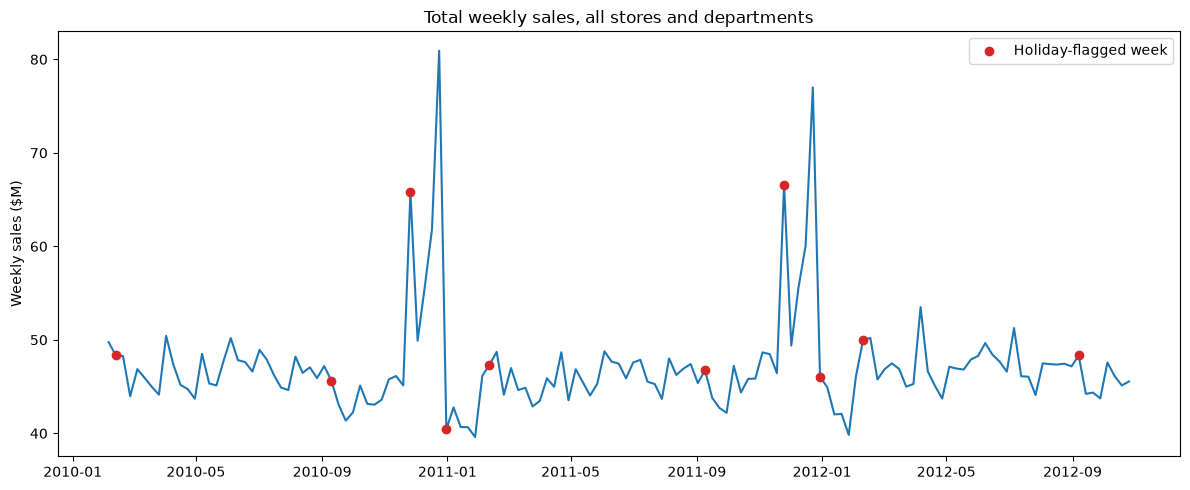

In [3]:
import matplotlib.pyplot as plt

neg = train[train.Weekly_Sales < 0]
total = train.Weekly_Sales.sum()
print("Total sales ($M):", round(total / 1e6, 1))
print("Negative rows total ($M):", round(neg.Weekly_Sales.sum() / 1e6, 2),
      "| % of total:", round(neg.Weekly_Sales.sum() / total * 100, 3))
print("Departments with most negative rows:\n", neg.Dept.value_counts().head(5), "\n")

print(pd.cut(weeks_per_series, bins=[0, 26, 71, 142, 143],
             labels=["26 weeks or fewer", "27-71", "72-142", "full (143)"])
        .value_counts().sort_index(), "\n")

weekly = train.groupby("Date").Weekly_Sales.sum()
print("Top 5 weeks ($M):\n", (weekly.nlargest(5) / 1e6).round(1), "\n")
print("Bottom 3 weeks ($M):\n", (weekly.nsmallest(3) / 1e6).round(1))

holiday_weeks = train.loc[train.IsHoliday, "Date"].drop_duplicates()
print("Holiday-flagged weeks:", len(holiday_weeks))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly.index, weekly / 1e6)
ax.scatter(holiday_weeks, weekly.loc[holiday_weeks] / 1e6, color="tab:red", zorder=3, label="Holiday-flagged week")
ax.set_title("Total weekly sales, all stores and departments")
ax.set_ylabel("Weekly sales ($M)")
ax.legend()
plt.tight_layout()
plt.show()

### Findings from the data quality check
- Total sales over 143 weeks: **$6,737M** (average week $47.1M).
- 1,285 negative rows total **-$0.09M (-0.001% of sales)** and are concentrated in a few departments (Depts 47, 18 and 54 hold 580 of them). They are kept so totals represent net sales.
- 2,660 of 3,331 store-department series (80%) cover all 143 weeks. 274 series have 26 weeks or fewer.
- Biggest weeks: the Friday before Christmas (Dec 24, 2010: $80.9M; Dec 23, 2011: $77.0M), then the weeks labeled with the Friday after Thanksgiving. Quietest weeks: late January (about $39.6M to $39.8M) and Dec 31, 2010 ($40.4M). Peak to trough is about 2x.
- The two late-January weeks are within 0.5% of each other (2011 vs 2012), a first hint of little year-over-year growth, to be tested.
- 10 weeks carry the holiday flag. Whether the flagged weeks coincide with sales peaks is checked next.

## 4. Aggregate to Monthly
Rules: (1) negative and zero rows are kept (net sales; negatives are -0.001% of total). (2) Each Friday belongs to the month of its date. (3) The main monthly measure is **average weekly sales** (total / number of weeks), because months have 4 or 5 Fridays. A **like-for-like** version uses only the series present in all 143 weeks, as a robustness check.

In [4]:
wk = train.groupby("Date").Weekly_Sales.sum().to_frame("sales")
wk["month"] = wk.index.to_period("M")

monthly = wk.groupby("month").agg(
    total_sales=("sales", "sum"),
    weeks=("sales", "count"),
    avg_weekly_sales=("sales", "mean"),
)

# Like-for-like: only series that report in all 143 weeks
full_series = weeks_per_series[weeks_per_series == 143].index
mask = train.set_index(["Store", "Dept"]).index.isin(full_series)
lfl = train[mask].groupby("Date").Weekly_Sales.sum().to_frame("sales")
lfl["month"] = lfl.index.to_period("M")
monthly["avg_weekly_lfl"] = lfl.groupby("month").sales.mean()

monthly = (monthly / 1e6).round(2).assign(weeks=monthly.weeks)
print(monthly.to_string())
print("\nMonths:", len(monthly), "| 4-Friday months:", (monthly.weeks == 4).sum(),
      "| 5-Friday months:", (monthly.weeks == 5).sum())
print("Share of total sales from full-length series (%):",
      round(train[mask].Weekly_Sales.sum() / train.Weekly_Sales.sum() * 100, 1))

flagged = sorted(train.loc[train.IsHoliday, "Date"].dt.date.unique())
print("\nHoliday-flagged dates:", flagged)

monthly.to_csv(PROCESSED_DIR / "monthly_sales.csv")

         total_sales  weeks  avg_weekly_sales  avg_weekly_lfl
month                                                        
2010-02       190.33      4             47.58           47.21
2010-03       181.92      4             45.48           45.31
2010-04       231.41      5             46.28           45.98
2010-05       186.71      4             46.68           46.55
2010-06       192.25      4             48.06           47.93
2010-07       232.58      5             46.52           46.39
2010-08       187.64      4             46.91           46.79
2010-09       177.27      4             44.32           44.12
2010-10       217.16      5             43.43           42.83
2010-11       202.85      4             50.71           49.87
2010-12       288.76      5             57.75           56.11
2011-01       163.70      4             40.93           40.73
2011-02       186.33      4             46.58           46.20
2011-03       179.36      4             44.84           44.68
2011-04 

### Findings from the monthly aggregation
- 33 months (Feb 2010 to Oct 2012): 22 with 4 Fridays, 11 with 5. **Monthly totals are jagged because of the extra week** (Sep 2011 total $220.9M vs Oct 2011 $183.3M, yet October's average week is higher: $45.8M vs $44.2M). **Average weekly sales** is the main monthly measure.
- Series present in all 143 weeks account for **99.1%** of sales. Their monthly averages are within about 2% of the all-series figures in most months and about 3% lower in December, possibly due to seasonal departments (not yet tested).
- **Peak: December** (about $57.7M per week in both years), then November ($50.7M and $52.5M). **Trough: January** ($40.9M and $42.2M). Feb to Oct months stay between $43M and $48M (about $46M on average): seasonality is concentrated in Nov, Dec and Jan.
- The 10 holiday-flagged weeks match the weeks containing Super Bowl (Feb), Labor Day (Sep), Thanksgiving (Nov) and Christmas (Dec). The flag is **not a peak marker**: the Christmas-flagged weeks (Dec 31, 2010 and Dec 30, 2011) fall after the rush, and the biggest weeks (Dec 24, 2010 and Dec 23, 2011) are unflagged.
- The flag pattern implies the Friday dates are **week-ending** dates. Each week is assigned to the month in which it ends.

## 5. Trend and Moving Averages
- Top panel: monthly totals, with 5-Friday months in a darker color, to show the extra-week effect.
- Bottom panel: average weekly sales per month with 3-month and 12-month moving averages. A 12-month average contains every calendar month once, so it removes seasonality and exposes the underlying trend. The 3-month average reduces noise but keeps the seasonal shape.
- Year-over-year change (same month, previous year) is computed as a cleaner trend measure.

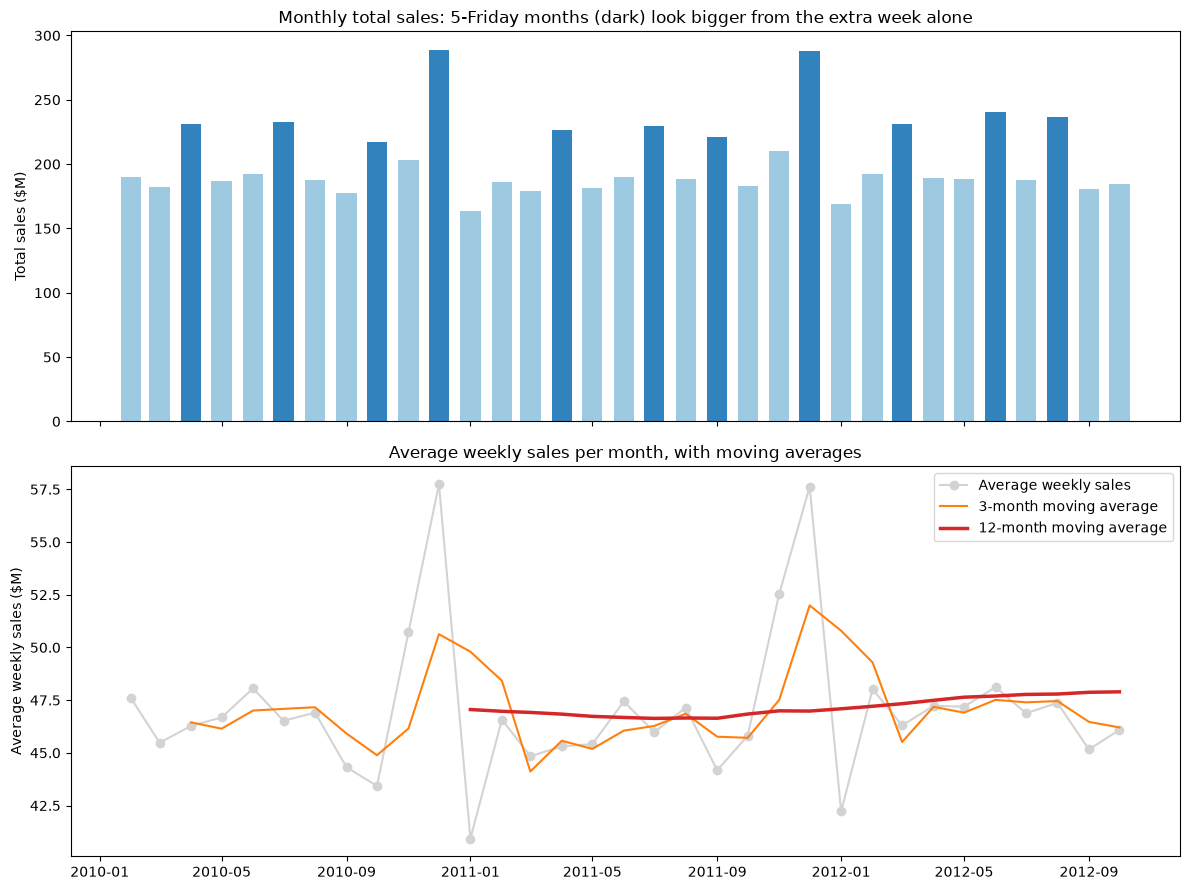

12-month moving average, first and last valid month:
month
2011-01-01    47.05
2012-10-01    47.90
Freq: 21MS, Name: ma12, dtype: float64 

Year-over-year change in average weekly sales (%):
month
2011-02-01   -2.1
2011-03-01   -1.4
2011-04-01   -2.1
2011-05-01   -2.7
2011-06-01   -1.3
2011-07-01   -1.2
2011-08-01    0.5
2011-09-01   -0.3
2011-10-01    5.5
2011-11-01    3.6
2011-12-01   -0.2
2012-01-01    3.2
2012-02-01    3.1
2012-03-01    3.3
2012-04-01    4.2
2012-05-01    3.9
2012-06-01    1.4
2012-07-01    2.0
2012-08-01    0.5
2012-09-01    2.2
2012-10-01    0.6
Freq: MS


In [5]:
m = monthly.copy()
m.index = m.index.to_timestamp()
m["ma3"]  = m.avg_weekly_sales.rolling(3).mean()
m["ma12"] = m.avg_weekly_sales.rolling(12).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

colors = m.weeks.map({4: "#9ecae1", 5: "#3182bd"})
ax1.bar(m.index, m.total_sales, width=20, color=colors.tolist())
ax1.set_title("Monthly total sales: 5-Friday months (dark) look bigger from the extra week alone")
ax1.set_ylabel("Total sales ($M)")

ax2.plot(m.index, m.avg_weekly_sales, color="lightgray", marker="o", label="Average weekly sales")
ax2.plot(m.index, m.ma3,  color="tab:orange", label="3-month moving average")
ax2.plot(m.index, m.ma12, color="tab:red", linewidth=2.5, label="12-month moving average")
ax2.set_title("Average weekly sales per month, with moving averages")
ax2.set_ylabel("Average weekly sales ($M)")
ax2.legend()

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "monthly_sales_trend.png", dpi=200)
plt.show()

print("12-month moving average, first and last valid month:")
print(m.ma12.dropna().iloc[[0, -1]].round(2), "\n")
yoy = m.avg_weekly_sales.pct_change(12).dropna() * 100
print("Year-over-year change in average weekly sales (%):")
print(yoy.round(1).to_string())

### Findings from trend and moving averages
- The **12-month moving average** (which removes seasonality) rose from $47.05M to $47.90M per week between Jan 2011 and Oct 2012: **+1.8% in 21 months (about 1% a year)**. The underlying level is nearly flat (nominal dollars, not adjusted for inflation).
- Year-over-year change in average weekly sales: **2011 was below 2010 from Feb to Jul** (-1.2% to -2.7%), about flat in Aug and Sep, and up in Oct (+5.5%) and Nov (+3.6%). **Every month of 2012 was above 2011**, averaging +3.5% in Jan to May and +1.3% in Jun to Oct.
- Oct 2011 (+5.5%) reflects a low Oct 2010 base (the lowest Feb to Oct month in the data) and is not a composition effect (like-for-like: +5.4%).
- The 2011 holiday season (Nov + Dec) grew only **+1.3%** over 2010 ($498.2M vs $491.6M).
- Whether the slowdown after May 2012 is a real change cannot be established from 5 months.

## 6. Seasonality and Holiday Weeks
- **Seasonal index:** multiplicative decomposition of monthly average weekly sales (`period=12`). Each month is compared with the centered 12-month trend, and the ratios are averaged by calendar month. The index shows how far a calendar month typically sits above or below the trend.
- **Limits:** the centered trend exists for only 21 of 33 months, so each calendar month rests on **1 to 2 observations**. Results are indicative.
- **Holiday weeks:** the 10 flagged weeks are compared with the average week to measure the lift.

     index  observations  vs_typical_%
Jan  0.882             2         -11.8
Feb  1.003             2           0.3
Mar  0.966             2          -3.4
Apr  0.979             2          -2.1
May  0.969             1          -3.1
Jun  1.011             1           1.1
Jul  0.979             1          -2.1
Aug  1.000             2           0.0
Sep  0.941             2          -5.9
Oct  0.948             2          -5.2
Nov  1.096             2           9.6
Dec  1.224             2          22.4 

Centered 12-month trend: Aug 2010 47.01 -> Apr 2012 47.88 



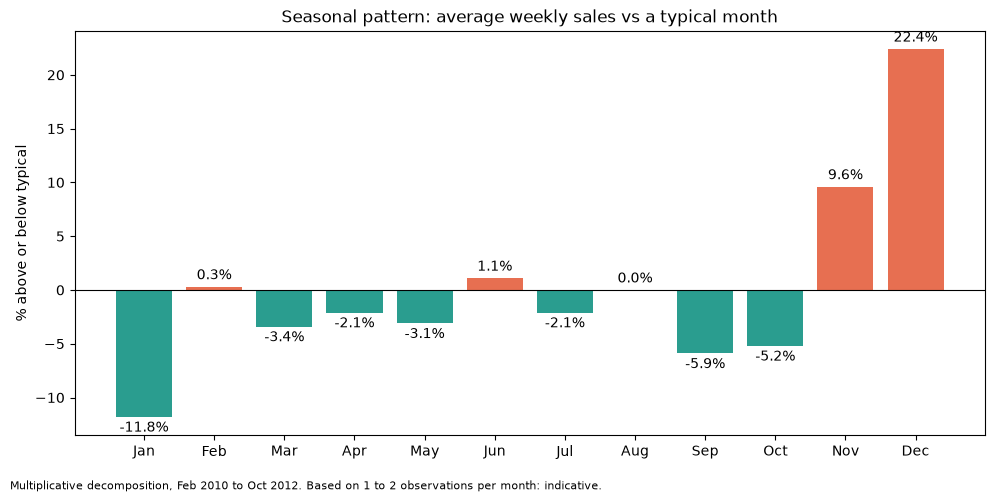

Average week ($M): 47.1
            sales_$M         event  lift_vs_avg_week_%
Date                                                  
2010-02-12      48.3    Super Bowl                 2.6
2010-09-10      45.6     Labor Day                -3.1
2010-11-26      65.8  Thanksgiving                39.7
2010-12-31      40.4     Christmas               -14.2
2011-02-11      47.3    Super Bowl                 0.5
2011-09-09      46.8     Labor Day                -0.7
2011-11-25      66.6  Thanksgiving                41.3
2011-12-30      46.0     Christmas                -2.3
2012-02-10      50.0    Super Bowl                 6.1
2012-09-07      48.3     Labor Day                 2.6

Average lift by event (%):
event
Christmas       -8.2
Labor Day       -0.4
Super Bowl       3.1
Thanksgiving    40.5
Name: lift_vs_avg_week_%, dtype: float64


In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

series = m.avg_weekly_sales
dec = seasonal_decompose(series, model="multiplicative", period=12)

ratio = series / dec.trend
season = pd.DataFrame({
    "index": dec.seasonal.groupby(dec.seasonal.index.month).first(),
    "observations": ratio.groupby(ratio.index.month).count(),
}).round(3)
season["vs_typical_%"] = ((season["index"] - 1) * 100).round(1)
season.index = [pd.Timestamp(2000, k, 1).strftime("%b") for k in season.index]
print(season, "\n")

valid = dec.trend.dropna()
print("Centered 12-month trend:", valid.index[0].strftime("%b %Y"), round(valid.iloc[0], 2),
      "->", valid.index[-1].strftime("%b %Y"), round(valid.iloc[-1], 2), "\n")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(season.index, season["vs_typical_%"],
              color=["#e76f51" if v > 0 else "#2a9d8f" for v in season["vs_typical_%"]])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Seasonal pattern: average weekly sales vs a typical month")
ax.set_ylabel("% above or below typical")
fig.text(0.01, 0.01, "Multiplicative decomposition, Feb 2010 to Oct 2012. Based on 1 to 2 observations per month: indicative.", fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(OUTPUT_DIR / "seasonal_index.png", dpi=200)
plt.show()

avg_week = weekly.mean()
hol = (weekly.loc[holiday_weeks].sort_index() / 1e6).to_frame("sales_$M")
hol["event"] = hol.index.month.map({2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas"})
hol["lift_vs_avg_week_%"] = ((hol["sales_$M"] / (avg_week / 1e6) - 1) * 100).round(1)
print("Average week ($M):", round(avg_week / 1e6, 1))
print(hol.round(1).to_string())
print("\nAverage lift by event (%):")
print(hol.groupby("event")["lift_vs_avg_week_%"].mean().round(1).sort_values())

### Findings from seasonality and holiday weeks
- **Seasonal index** (multiplicative decomposition of monthly average weekly sales, relative to the 12-month trend): **December +22.4%, November +9.6%, January -11.8%**. September and October sit about 5% to 6% below the trend. February to August stay within about ±3.4%: no clear seasonal signal.
- Each calendar month rests on 1 to 2 observations (May, Jun and Jul on one), so the index is indicative. December and January each have two years that agree closely.
- The centered trend rises from $47.01M (Aug 2010) to $47.88M (Apr 2012), **+1.9%**, matching the moving-average result (+1.8%): the underlying level is nearly flat.
- Holiday-flagged weeks vs the average week ($47.1M): **Thanksgiving +40.5%** (the only strong lift), Super Bowl +3.1%, Labor Day -0.4%, Christmas -8.2%. The Christmas flag marks the week *after* the pre-Christmas rush, so the flag should not be read as a peak indicator.
- These lifts are measured against the overall average week and include seasonal effects (September is about 6% below the trend).

## 7. Breakdown by Product (Department)
- Departments are anonymized numbers, so they are compared by number only.
- Revenue concentration: sales per department, share of total, cumulative share, and how many stores carry it.
- Seasonality per department: average weekly sales in Nov to Dec weeks divided by average weekly sales in Feb to Oct weeks (departments with 1%+ of sales only, to avoid noisy ratios).
- Chart: monthly average weekly sales for the top 5 departments.

      sales_$M  share_%  cum_share_%  stores
Dept                                        
92       483.9      7.2          7.2      45
95       449.3      6.7         13.9      45
38       393.1      5.8         19.7      45
72       305.7      4.5         24.2      45
90       291.1      4.3         28.5      45
40       288.9      4.3         32.8      45
2        280.6      4.2         37.0      45
91       216.8      3.2         40.2      45
13       197.3      2.9         43.1      45
8        194.3      2.9         46.0      45 

Departments for 50% of sales: 12 | for 80%: 29 | of 81 

Departments with 1%+ of sales: 33
Most seasonal:
 Dept
7     2.75
5     2.28
72    1.94
14    1.74
82    1.67
Name: nov_dec_vs_feb_oct, dtype: float64 

Least seasonal:
 Dept
16    0.21
3     0.81
94    0.85
9     0.88
95    0.90
Name: nov_dec_vs_feb_oct, dtype: float64 

Median ratio across these departments: 1.02


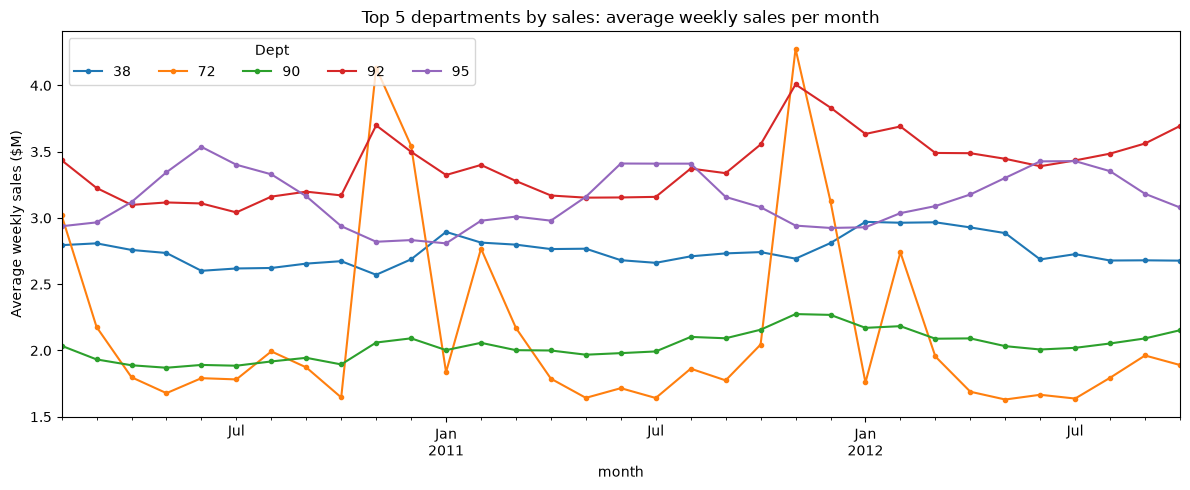

In [7]:
dept_total = train.groupby("Dept").Weekly_Sales.sum().sort_values(ascending=False)
share = dept_total / dept_total.sum() * 100

stores_per_dept = train.groupby("Dept").Store.nunique().reindex(dept_total.index)
top = pd.DataFrame({
    "sales_$M": dept_total / 1e6,
    "share_%": share,
    "cum_share_%": share.cumsum(),
    "stores": stores_per_dept,
}).head(10).round(1)
print(top.to_string(), "\n")
print("Departments for 50% of sales:", int((share.cumsum() < 50).sum() + 1),
      "| for 80%:", int((share.cumsum() < 80).sum() + 1), "| of", len(dept_total), "\n")

dw = train.groupby(["Dept", "Date"]).Weekly_Sales.sum().reset_index()
dw["cal_month"] = dw.Date.dt.month
nov_dec = dw[dw.cal_month.isin([11, 12])].groupby("Dept").Weekly_Sales.mean()
feb_oct = dw[dw.cal_month.between(2, 10)].groupby("Dept").Weekly_Sales.mean()
uplift = (nov_dec / feb_oct).rename("nov_dec_vs_feb_oct")

big = share[share >= 1].index
print("Departments with 1%+ of sales:", len(big))
print("Most seasonal:\n", uplift.loc[big].sort_values(ascending=False).round(2).head(5), "\n")
print("Least seasonal:\n", uplift.loc[big].sort_values().round(2).head(5), "\n")
print("Median ratio across these departments:", round(uplift.loc[big].median(), 2))

top5 = dept_total.head(5).index
dm = dw[dw.Dept.isin(top5)].copy()
dm["month"] = dm.Date.dt.to_period("M").dt.to_timestamp()
dm = dm.groupby(["month", "Dept"]).Weekly_Sales.mean().unstack() / 1e6

fig, ax = plt.subplots(figsize=(12, 5))
dm.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Top 5 departments by sales: average weekly sales per month")
ax.set_ylabel("Average weekly sales ($M)")
ax.legend(title="Dept", ncol=5)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "top5_departments_over_time.png", dpi=200)
plt.show()

### Findings: by department
- **Dept 92 is the largest department ($483.9M, 7.2% of sales)**, followed by Dept 95 (6.7%) and Dept 38 (5.8%). The top 3 account for 19.7% and the top 10 for 46.0%. All of the top 10 are carried by all 45 stores.
- Sales are spread across many departments: **12 of 81 produce 50% of sales and 29 produce 80%**.
- Department seasonality (Nov to Dec average weekly sales vs Feb to Oct), for the 33 departments with 1%+ of sales: most seasonal **Dept 7 (2.75x), Dept 5 (2.28x), Dept 72 (1.94x)**; least seasonal **Dept 16 (0.21x)**, then Depts 3, 94, 9 and 95 (0.81x to 0.90x).
- Size and seasonality are unrelated: Dept 95, the second largest, is among the least seasonal (0.90x), while Dept 72, the fourth largest, is among the most seasonal (1.94x).
- The median department has a ratio of only **1.02**, versus about 1.19 company-wide: the holiday bump is driven by a minority of departments.
- Department numbers are anonymized, so findings are by number only. Dept 16's ratio has not been checked for incomplete reporting.

## 8. Breakdown by Region (Store and Store Type)
- Stores are anonymized numbers. `Type` (A, B, C) and `Size` come from `stores.csv`.
- Compare types by average weekly sales **per store** (the types have 22, 17 and 6 stores) and by weekly sales **per square foot**.
- Check whether stores carry the same number of departments, since that affects store totals.
- Chart: average weekly sales per store by type, per month.

      stores   avg_size  avg_weekly_sales  per_sqft  share_of_sales_%
Type                                                                 
A         22  177247.73        1376673.47      7.74              64.3
B         17  101190.71         822994.96      8.35              29.7
C          6   40541.67         472614.83     11.66               6.0 

Departments per store: min 61 | max 79
Type
A    76.0
B    75.6
C    62.3
Name: Dept, dtype: float64 

Top 3 stores:
  Store Type   Size  avg_weekly_sales  per_sqft
    20    A 203742         2107677.0      10.0
     4    A 205863         2094713.0      10.0
    14    A 200898         2020978.0      10.0
Bottom 3 stores:
  Store Type  Size  avg_weekly_sales  per_sqft
     5    B 34875          318012.0       9.0
    44    C 39910          302749.0       8.0
    33    A 39690          259862.0       7.0


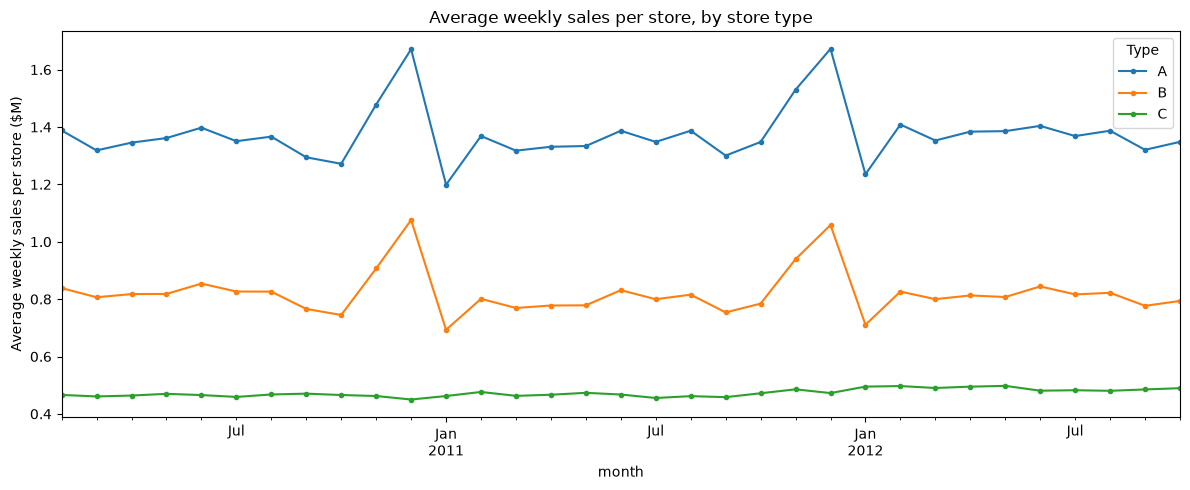

In [8]:
ts = train.merge(stores, on="Store", how="left")
assert len(ts) == len(train) and ts.Type.notna().all()

sw = ts.groupby(["Store", "Type", "Size", "Date"], as_index=False).Weekly_Sales.sum()
by_store = (sw.groupby(["Store", "Type", "Size"], as_index=False).Weekly_Sales.mean()
              .rename(columns={"Weekly_Sales": "avg_weekly_sales"}))
by_store["per_sqft"] = by_store.avg_weekly_sales / by_store.Size

by_type = by_store.groupby("Type").agg(
    stores=("Store", "count"),
    avg_size=("Size", "mean"),
    avg_weekly_sales=("avg_weekly_sales", "mean"),
    per_sqft=("per_sqft", "mean"),
).round(2)
by_type["share_of_sales_%"] = (ts.groupby("Type").Weekly_Sales.sum() / ts.Weekly_Sales.sum() * 100).round(1)
print(by_type, "\n")

depts_per_store = train.groupby("Store").Dept.nunique()
print("Departments per store: min", depts_per_store.min(), "| max", depts_per_store.max())
print(depts_per_store.groupby(stores.set_index("Store").Type).mean().round(1), "\n")

show = by_store.sort_values("avg_weekly_sales", ascending=False)
print("Top 3 stores:\n", show.head(3).round(0).to_string(index=False))
print("Bottom 3 stores:\n", show.tail(3).round(0).to_string(index=False))

tw = ts.groupby(["Type", "Date"]).Weekly_Sales.sum().reset_index()
tw["per_store"] = tw.Weekly_Sales / tw.Type.map(stores.Type.value_counts()) / 1e6
tw["month"] = tw.Date.dt.to_period("M").dt.to_timestamp()
tm = tw.groupby(["month", "Type"]).per_store.mean().unstack()

fig, ax = plt.subplots(figsize=(12, 5))
tm.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Average weekly sales per store, by store type")
ax.set_ylabel("Average weekly sales per store ($M)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "sales_per_store_by_type.png", dpi=200)
plt.show()

### Findings: by store and store type
- **Type A** (22 stores, 49% of stores) generates **64.3%** of sales; B (17 stores) 29.7%; C (6 stores) 6.0%. The type averages reconcile to the $47.1M average weekly total.
- Average weekly sales per store: **A $1.38M, B $0.82M, C $0.47M**. A is 2.9x C in sales but 4.4x in size.
- **Sales per square foot are highest for the smallest stores:** C $11.66, B $8.35, A $7.74 (assuming `Size` is square feet). Type C stores also carry fewer departments (62 on average vs 76 for A and 76 for B), so the comparison is not like-for-like.
- No store carries all 81 departments (range 61 to 79).
- Type is not purely a size class: Store 33 is Type A at only 39,690 sq ft and is the weakest store ($260K a week), while Store 5 (Type B) is 34,875 sq ft.
- The best store (20: $2.11M a week) sells about 8x the weakest (33).

## 9. Bonus: Simple Forecast
- Series: monthly average weekly sales (33 months). **Train:** Feb 2010 to Apr 2012 (27 months). **Test:** May to Oct 2012 (6 months).
- Methods: naive (last value), 3-month rolling mean, seasonal naive (same month last year) and Holt-Winters exponential smoothing (multiplicative seasonality, no trend).
- Metrics on the held-out months: MAE ($M) and MAPE (%).
- **Limit:** the test window contains no holiday months, so it cannot show whether a method captures the Nov to Dec peak. A forecast for Nov 2012 to Jan 2013 is shown for illustration only.
- Forecasts are for *average weekly sales*. Multiply by the number of Fridays to get a monthly total (Nov 2012: 5, Dec 2012: 4, Jan 2013: 4).

                MAE_$M  MAPE_%
holt_winters      0.64    1.38
rolling_mean_3    0.76    1.64
naive             0.77    1.67
seasonal_naive    0.81    1.72 

Holt-Winters forecast, average weekly sales ($M):
 2012-11-01    52.37
2012-12-01    58.54
2013-01-01    42.44
Freq: MS, dtype: float64 

Same months last year:
 month
2011-11-01    52.54
2011-12-01    57.62
2012-01-01    42.22
Freq: MS, Name: avg_weekly_sales, dtype: float64


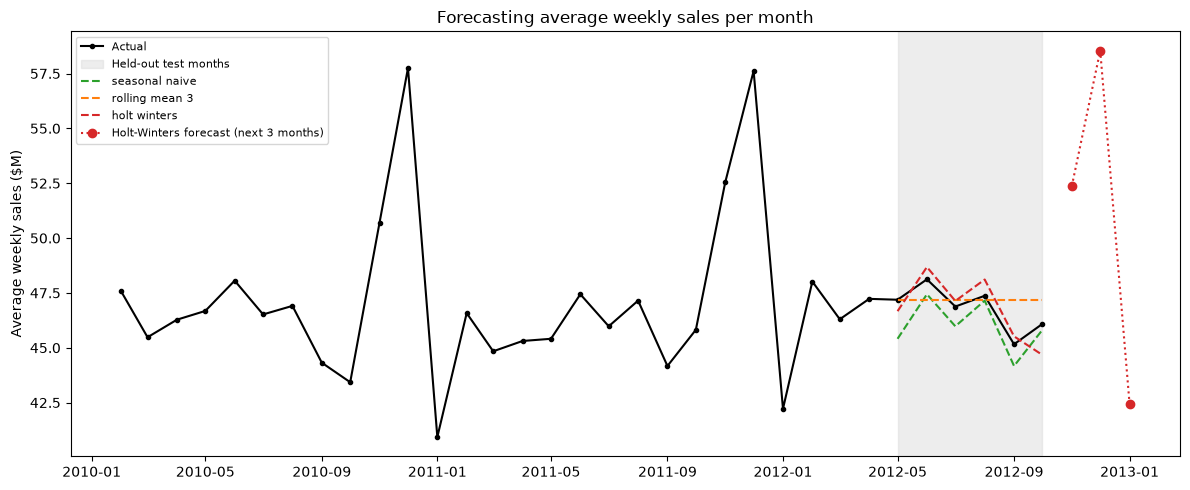

In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

series = m.avg_weekly_sales
train_m, test_m = series.iloc[:-6], series.iloc[-6:]

forecasts = pd.DataFrame(index=test_m.index)
forecasts["naive"] = train_m.iloc[-1]
forecasts["rolling_mean_3"] = train_m.iloc[-3:].mean()
forecasts["seasonal_naive"] = series.shift(12).loc[test_m.index]
hw = ExponentialSmoothing(train_m, trend=None, seasonal="mul", seasonal_periods=12,
                          initialization_method="heuristic").fit()
forecasts["holt_winters"] = hw.forecast(6)

def score(f):
    err = (test_m - f).abs()
    return pd.Series({"MAE_$M": err.mean(), "MAPE_%": (err / test_m).mean() * 100})

results = forecasts.apply(score).T.round(2).sort_values("MAPE_%")
print(results, "\n")

hw_full = ExponentialSmoothing(series, trend=None, seasonal="mul", seasonal_periods=12,
                               initialization_method="heuristic").fit()
future = hw_full.forecast(3)
print("Holt-Winters forecast, average weekly sales ($M):\n", future.round(2), "\n")
print("Same months last year:\n", series.loc["2011-11-01":"2012-01-01"].round(2))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(series.index, series, color="black", marker="o", markersize=3, label="Actual")
ax.axvspan(test_m.index[0], test_m.index[-1], color="lightgray", alpha=0.4, label="Held-out test months")
for col, c in [("seasonal_naive", "tab:green"), ("rolling_mean_3", "tab:orange"), ("holt_winters", "tab:red")]:
    ax.plot(forecasts.index, forecasts[col], color=c, linestyle="--", label=col.replace("_", " "))
ax.plot(future.index, future, color="tab:red", linestyle=":", marker="o", label="Holt-Winters forecast (next 3 months)")
ax.set_title("Forecasting average weekly sales per month")
ax.set_ylabel("Average weekly sales ($M)")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "forecast_comparison.png", dpi=200)
plt.show()

### Findings: forecast
- **Setup:** train Feb 2010 to Apr 2012 (27 months), test May to Oct 2012 (6 months), forecasting monthly average weekly sales.
- **Holt-Winters** (multiplicative seasonality, no trend) scored best: **MAPE 1.38%, MAE $0.64M per week**. Rolling mean 1.64%, naive 1.67%, seasonal naive 1.72%.
- The methods are close because the test window is flat. The naive error is already 1.67%, and the ranking rests on 6 months, so the advantage is slight.
- Seasonal naive under-forecast every test month: it ignores year-over-year growth (about 1.8% on average over these months).
- **The test window has no holiday months**, so it cannot show whether any method captures the Nov to Dec peak.
- Illustrative Holt-Winters forecast (average weekly sales): **Nov 2012 $52.4M, Dec $58.5M, Jan 2013 $42.4M**, vs $52.5M, $57.6M and $42.2M a year earlier. No prediction intervals; one train-test split; seasonal pattern learned from about two cycles.
- Converting to monthly totals requires multiplying by the number of Fridays (5, 4, 4): month-to-month swings in totals partly reflect the calendar.